## 1. 메뉴 2개, 재료 3개, 최대 주문 대기 수 2개 (Reward 초기조건 그대로)

Episode [50/2000] | Total Reward: -43.80
Episode [100/2000] | Total Reward: -26.70
Episode [150/2000] | Total Reward: -30.60
Episode [200/2000] | Total Reward: -30.70
Episode [250/2000] | Total Reward: -41.70
Episode [300/2000] | Total Reward: -20.50
Episode [350/2000] | Total Reward: -20.40
Episode [400/2000] | Total Reward: -20.60
Episode [450/2000] | Total Reward: -20.70
Episode [500/2000] | Total Reward: -20.50
Episode [550/2000] | Total Reward: -22.80
Episode [600/2000] | Total Reward: -22.80
Episode [650/2000] | Total Reward: -20.60
Episode [700/2000] | Total Reward: -20.80
Episode [750/2000] | Total Reward: -20.50
Episode [800/2000] | Total Reward: -20.70
Episode [850/2000] | Total Reward: -20.70
Episode [900/2000] | Total Reward: -20.60
Episode [950/2000] | Total Reward: -20.80
Episode [1000/2000] | Total Reward: -20.70
Episode [1050/2000] | Total Reward: -20.60
Episode [1100/2000] | Total Reward: -20.70
Episode [1150/2000] | Total Reward: -20.80
Episode [1200/2000] | Total Rew

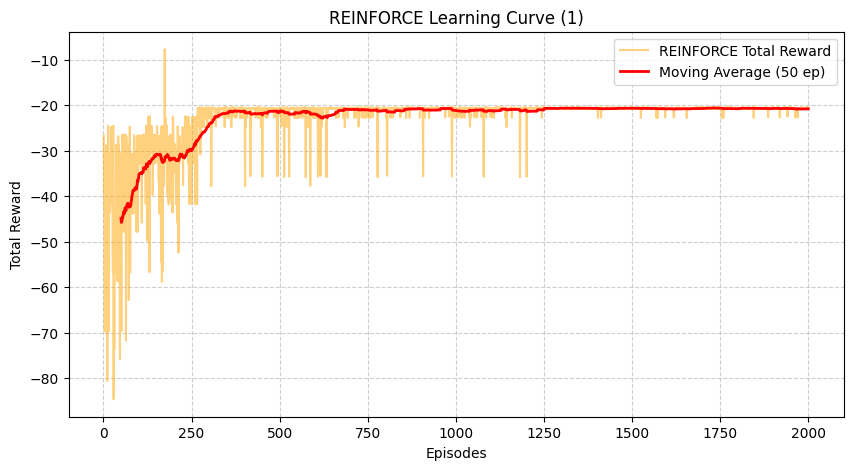

In [ ]:
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# 1. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 2

        # State: [d, c, p, m1, t1, m2, t2] = 7 dim
        # d, c, p: 0 or 1
        # m1, m2: 0 (No order), 1 (Cheese), 2 (Pepperoni)
        # t1, t2: 0 to 8 (Normalized by 8.0)
        self.observation_space = spaces.Box(
            low=0.0,
            high=np.array([1, 1, 1, 2, 1, 2, 1], dtype=np.float32),
            dtype=np.float32
        )
        self.action_space = spaces.Discrete(5)
        # 0: Idle, 1: Add Dough (d), 2: Add Cheese (c), 3: Add Pepperoni (p), 4: Serve

        self.menus = {
            1: [1.0, 1.0, 0.0], # Cheese Pizza: Dough + Cheese
            2: [1.0, 1.0, 1.0]  # Pepperoni Pizza: Dough + Cheese + Pepperoni
        }

        self.reset()

    def reset(self, seed=None):
        super().reset(seed=seed)
        self.counter = np.zeros(3, dtype=np.float32) # [d, c, p]
        self.orders = []

        # Initialize 2 orders with timer 4~8 steps
        for _ in range(self.max_orders):
            self._add_order()

        self.steps = 0
        self.terminated_count = 0
        return self._get_obs(), {}

    def _add_order(self):
        if len(self.orders) < self.max_orders:
            menu_id = np.random.choice([1, 2]) # Cheese or Pepperoni
            timer = np.random.randint(4, 9)     # 4 to 8 steps
            self.orders.append({'menu_id': menu_id, 'timer': timer})

    def _get_obs(self):
        obs = list(self.counter)
        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.append(float(self.orders[i]['menu_id']))
                obs.append(float(self.orders[i]['timer']) / 8.0)
            else:
                obs.append(0.0)
                obs.append(0.0)
        return np.array(obs, dtype=np.float32)

    def step(self, action):
        self.steps += 1
        reward = -0.1 # Every action penalty
        terminated = False
        truncated = self.steps >= 100

        # 1. Action Processing & Rule Checking
        if action == 1: # Add Dough
            if self.counter[0] == 1.0:
                reward -= 2.0 # Duplicate ingredient penalty
            else:
                self.counter[0] = 1.0
        elif action == 2: # Add Cheese
            if self.counter[1] == 1.0:
                reward -= 2.0 # Duplicate ingredient penalty
            elif self.counter[0] == 0.0:
                reward -= 2.0 # Incorrect sequence (needs dough first)
            else:
                self.counter[1] = 1.0
        elif action == 3: # Add Pepperoni
            if self.counter[2] == 1.0:
                reward -= 2.0 # Duplicate ingredient penalty
            elif self.counter[0] == 0.0 or self.counter[1] == 0.0:
                reward -= 2.0 # Incorrect sequence (needs dough & cheese first)
            else:
                self.counter[2] = 1.0
        elif action == 4: # Serve (FIFO based on orders[0])
            if len(self.orders) > 0:
                target_menu = self.orders[0]['menu_id']
                target_recipe = self.menus[target_menu]

                if np.array_equal(self.counter, target_recipe):
                    reward += 20.0 # Correct serve
                    self.orders.pop(0)
                    self.counter = np.zeros(3, dtype=np.float32) # Reset counter on correct serve
                else:
                    reward -= 15.0 # Incorrect serve penalty
                    self.counter = np.zeros(3, dtype=np.float32) # Reset counter on incorrect serve
                    # Orders kept as is, timer decreases below in timer loop
            else:
                reward -= 1.0 # Serve with no orders

        # 2. Timer Update & Timeout Check for Waiting Orders
        orders_to_remove = []
        for order in self.orders:
            order['timer'] -= 1.0
            if order['timer'] <= 0:
                reward -= 10.0 # Timeout penalty
                orders_to_remove.append(order)

        for expired in orders_to_remove:
            if expired in self.orders:
                self.orders.remove(expired)

        # Episode termination condition: All orders completed or canceled
        if len(self.orders) == 0:
            terminated = True

        return self._get_obs(), reward, terminated, truncated, {}

# 2. Define Policy Network
class PolicyNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(PolicyNetwork, self).__init__()
        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, action_dim)
        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.softmax(self.fc3(x))
        return x

# 3. REINFORCE Training Function with History Tracking
def train_reinforce(env, policy_net, optimizer, num_episodes=2000, gamma=0.99):
    reward_history = []

    for episode in range(num_episodes):
        state, _ = env.reset()
        log_probs = []
        rewards = []

        done = False
        while not done:
            state_tensor = torch.FloatTensor(state).unsqueeze(0)
            probs = policy_net(state_tensor)

            m = torch.distributions.Categorical(probs)
            action = m.sample()

            log_probs.append(m.log_prob(action))

            next_state, reward, terminated, truncated, info = env.step(action.item())
            done = terminated or truncated

            rewards.append(reward)
            state = next_state

        total_reward = sum(rewards)
        reward_history.append(total_reward)

        # Calculate returns (Discounted cumulative rewards)
        returns = []
        G = 0
        for r in reversed(rewards):
            G = r + gamma * G
            returns.insert(0, G)

        returns = torch.tensor(returns, dtype=torch.float32)

        # Normalize returns for stability
        if len(returns) > 1 and returns.std() > 0:
            returns = (returns - returns.mean()) / (returns.std() + 1e-8)

        # Policy gradient update
        optimizer.zero_grad()
        policy_loss = []
        for log_prob, G in zip(log_probs, returns):
            policy_loss.append(-log_prob * G)

        loss = torch.sum(torch.stack(policy_loss))
        loss.backward()
        optimizer.step()

        if (episode + 1) % 50 == 0:
            print(f"Episode [{episode+1}/{num_episodes}] | Total Reward: {total_reward:.2f}")

    return reward_history

# 4. Execution
env = PizzaShopEnv()
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

policy_net = PolicyNetwork(state_dim, action_dim)
optimizer = optim.Adam(policy_net.parameters(), lr=0.001)

rewards_history = train_reinforce(env, policy_net, optimizer, num_episodes=2000)

# 5. Visualization
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(rewards_history) + 1), rewards_history, label='REINFORCE Total Reward', color='orange', alpha=0.5)

window_size = 50
if len(rewards_history) >= window_size:
    moving_avg = np.convolve(rewards_history, np.ones(window_size)/window_size, mode='valid')
    plt.plot(range(window_size, len(rewards_history) + 1), moving_avg, label=f'Moving Average ({window_size} ep)', color='red', linewidth=2)

plt.title('REINFORCE Learning Curve (1)')
plt.xlabel('Episodes')
plt.ylabel('Total Reward')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**현상**:

초기 보상 체계 하에서 에이전트가 피자 제작에 성공하지 못하고, 주문 2개의 타임아웃 페널티 합계인 -20점 부근에 수렴하는 현상이 관찰됨.

**원인 분석**:

잘못된 서빙에 대한 페널티(-15)와 잘못된 재료 조작에 대한 페널티(-2)가 존재하는 상황에서, 에이전트가 성공적인 피자 제작 경로를 탐색하지 못할 경우 잘못된 행동을 반복하는 것보다 시간 초과로 에피소드가 종료되는 것이 상대적으로 적은 손실을 가져올 수 있음.

이로 인해 에이전트가 성공적인 피자 제작 행동을 충분히 학습하지 못하고, 결과적으로 타임아웃에 도달하는 소극적인 행동 패턴을 보였을 가능성이 있음.

**결론 및 시사점**:

초기 보상 체계에서는 성공적인 피자 제작을 유도하기에 충분한 학습 신호가 형성되지 않았으며, 에이전트가 시간 초과에 따른 손실을 반복하는 현상이 나타남.

따라서 에이전트가 성공적인 피자 제작 경로를 학습할 수 있도록 타임아웃 페널티와 정답 서빙 보상 간의 균형을 재조정할 필요가 있음.

이를 위해 다음 실험에서는 타임아웃 페널티를 강화하여 보상 구조의 변화가 학습 성능에 미치는 영향을 확인하고자 함.

####
## 2. 메뉴 2개, 재료 3개, 최대 주문 대기 수 2개 (Reward 타임아웃 페널티 -50으로 변경)

Episode [50/2000] | Total Reward: -102.60
Episode [100/2000] | Total Reward: -104.80
Episode [150/2000] | Total Reward: -106.80
Episode [200/2000] | Total Reward: -102.60
Episode [250/2000] | Total Reward: -100.70
Episode [300/2000] | Total Reward: -100.80
Episode [350/2000] | Total Reward: -102.80
Episode [400/2000] | Total Reward: -100.80
Episode [450/2000] | Total Reward: -100.80
Episode [500/2000] | Total Reward: -100.70
Episode [550/2000] | Total Reward: -100.70
Episode [600/2000] | Total Reward: -100.50
Episode [650/2000] | Total Reward: -100.70
Episode [700/2000] | Total Reward: -100.60
Episode [750/2000] | Total Reward: -100.70
Episode [800/2000] | Total Reward: -100.60
Episode [850/2000] | Total Reward: -100.70
Episode [900/2000] | Total Reward: -100.50
Episode [950/2000] | Total Reward: -100.70
Episode [1000/2000] | Total Reward: -100.70
Episode [1050/2000] | Total Reward: -100.70
Episode [1100/2000] | Total Reward: -100.70
Episode [1150/2000] | Total Reward: -100.80
Episode 

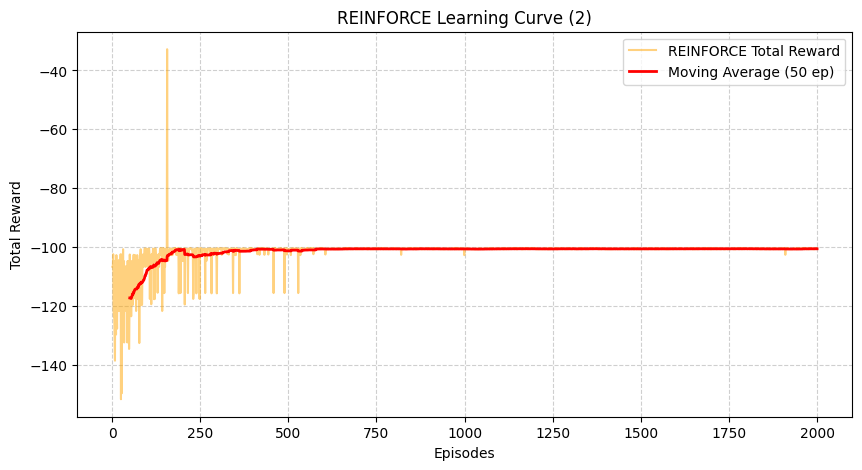

In [ ]:
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# 1. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 2

        # State: [d, c, p, m1, t1, m2, t2] = 7 dim
        # d, c, p: 0 or 1
        # m1, m2: 0 (No order), 1 (Cheese), 2 (Pepperoni)
        # t1, t2: 0 to 8 (Normalized by 8.0)
        self.observation_space = spaces.Box(
            low=0.0,
            high=np.array([1, 1, 1, 2, 1, 2, 1], dtype=np.float32),
            dtype=np.float32
        )
        self.action_space = spaces.Discrete(5)
        # 0: Idle, 1: Add Dough (d), 2: Add Cheese (c), 3: Add Pepperoni (p), 4: Serve

        self.menus = {
            1: [1.0, 1.0, 0.0], # Cheese Pizza: Dough + Cheese
            2: [1.0, 1.0, 1.0]  # Pepperoni Pizza: Dough + Cheese + Pepperoni
        }

        self.reset()

    def reset(self, seed=None):
        super().reset(seed=seed)
        self.counter = np.zeros(3, dtype=np.float32) # [d, c, p]
        self.orders = []

        # Initialize 2 orders with timer 4~8 steps
        for _ in range(self.max_orders):
            self._add_order()

        self.steps = 0
        self.terminated_count = 0
        return self._get_obs(), {}

    def _add_order(self):
        if len(self.orders) < self.max_orders:
            menu_id = np.random.choice([1, 2]) # Cheese or Pepperoni
            timer = np.random.randint(4, 9)     # 4 to 8 steps
            self.orders.append({'menu_id': menu_id, 'timer': timer})

    def _get_obs(self):
        obs = list(self.counter)
        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.append(float(self.orders[i]['menu_id']))
                obs.append(float(self.orders[i]['timer']) / 8.0)
            else:
                obs.append(0.0)
                obs.append(0.0)
        return np.array(obs, dtype=np.float32)

    def step(self, action):
        self.steps += 1
        reward = -0.1 # Every action penalty
        terminated = False
        truncated = self.steps >= 100

        # 1. Action Processing & Rule Checking
        if action == 1: # Add Dough
            if self.counter[0] == 1.0:
                reward -= 2.0 # Duplicate ingredient penalty
            else:
                self.counter[0] = 1.0
        elif action == 2: # Add Cheese
            if self.counter[1] == 1.0:
                reward -= 2.0 # Duplicate ingredient penalty
            elif self.counter[0] == 0.0:
                reward -= 2.0 # Incorrect sequence (needs dough first)
            else:
                self.counter[1] = 1.0
        elif action == 3: # Add Pepperoni
            if self.counter[2] == 1.0:
                reward -= 2.0 # Duplicate ingredient penalty
            elif self.counter[0] == 0.0 or self.counter[1] == 0.0:
                reward -= 2.0 # Incorrect sequence (needs dough & cheese first)
            else:
                self.counter[2] = 1.0
        elif action == 4: # Serve (FIFO based on orders[0])
            if len(self.orders) > 0:
                target_menu = self.orders[0]['menu_id']
                target_recipe = self.menus[target_menu]

                if np.array_equal(self.counter, target_recipe):
                    reward += 20.0 # Correct serve
                    self.orders.pop(0)
                    self.counter = np.zeros(3, dtype=np.float32) # Reset counter on correct serve
                else:
                    reward -= 15.0 # Incorrect serve penalty
                    self.counter = np.zeros(3, dtype=np.float32) # Reset counter on incorrect serve
            else:
                reward -= 1.0 # Serve with no orders

        # 2. Timer Update & Timeout Check for Waiting Orders
        orders_to_remove = []
        for order in self.orders:
            order['timer'] -= 1.0
            if order['timer'] <= 0:
                reward -= 50.0 # ⭐ Timeout penalty (-10 -> -50)
                orders_to_remove.append(order)

        for expired in orders_to_remove:
            if expired in self.orders:
                self.orders.remove(expired)

        # Episode termination condition: All orders completed or canceled
        if len(self.orders) == 0:
            terminated = True

        return self._get_obs(), reward, terminated, truncated, {}

# 2. Define Policy Network
class PolicyNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(PolicyNetwork, self).__init__()
        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, action_dim)
        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.softmax(self.fc3(x))
        return x

# 3. REINFORCE Training Function with History Tracking
def train_reinforce(env, policy_net, optimizer, num_episodes=2000, gamma=0.99):
    reward_history = []

    for episode in range(num_episodes):
        state, _ = env.reset()
        log_probs = []
        rewards = []

        done = False
        while not done:
            state_tensor = torch.FloatTensor(state).unsqueeze(0)
            probs = policy_net(state_tensor)

            m = torch.distributions.Categorical(probs)
            action = m.sample()

            log_probs.append(m.log_prob(action))

            next_state, reward, terminated, truncated, info = env.step(action.item())
            done = terminated or truncated

            rewards.append(reward)
            state = next_state

        total_reward = sum(rewards)
        reward_history.append(total_reward)

        # Calculate returns (Discounted cumulative rewards)
        returns = []
        G = 0
        for r in reversed(rewards):
            G = r + gamma * G
            returns.insert(0, G)

        returns = torch.tensor(returns, dtype=torch.float32)

        # Normalize returns for stability
        if len(returns) > 1 and returns.std() > 0:
            returns = (returns - returns.mean()) / (returns.std() + 1e-8)

        # Policy gradient update
        optimizer.zero_grad()
        policy_loss = []
        for log_prob, G in zip(log_probs, returns):
            policy_loss.append(-log_prob * G)

        loss = torch.sum(torch.stack(policy_loss))
        loss.backward()
        optimizer.step()

        if (episode + 1) % 50 == 0:
            print(f"Episode [{episode+1}/{num_episodes}] | Total Reward: {total_reward:.2f}")

    return reward_history

# 4. Execution
env = PizzaShopEnv()
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

policy_net = PolicyNetwork(state_dim, action_dim)
optimizer = optim.Adam(policy_net.parameters(), lr=0.001)

rewards_history = train_reinforce(env, policy_net, optimizer, num_episodes=2000)

# 5. Visualization
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(rewards_history) + 1), rewards_history, label='REINFORCE Total Reward', color='orange', alpha=0.5)

window_size = 50
if len(rewards_history) >= window_size:
    moving_avg = np.convolve(rewards_history, np.ones(window_size)/window_size, mode='valid')
    plt.plot(range(window_size, len(rewards_history) + 1), moving_avg, label=f'Moving Average ({window_size} ep)', color='red', linewidth=2)

plt.title('REINFORCE Learning Curve (2)')
plt.xlabel('Episodes')
plt.ylabel('Total Reward')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**현상**:

타임아웃 페널티를 -10에서 -50으로 강화하고 정답 서빙 보상은 +20으로 유지한 결과, 학습이 진행되어도 점수가 개선되지 않고 주문 2개의 타임아웃 페널티 합계인 -100점 부근에 수렴하는 현상이 관찰됨.

**원인 분석**:

타임아웃 페널티가 크게 증가했음에도 에이전트가 성공적인 피자 제작 경로를 충분히 탐색하지 못한 것으로 보임.

현재 환경에서는 잘못된 재료 선택이나 서빙 행동에도 추가적인 감점이 발생하므로, 성공적인 행동 순서를 학습하지 못한 에이전트는 피자 제작을 적극적으로 시도하기보다 추가 감점을 최소화하는 소극적인 행동을 선택했을 가능성이 있음.

즉, 타임아웃 페널티의 강화만으로는 에이전트가 성공적인 행동 경로를 발견하고 학습하도록 유도하기 어려웠던 것으로 해석할 수 있음.

**결론 및 시사점**:

타임아웃 페널티만 일방적으로 강화하는 방식으로는 에이전트의 성공적인 행동을 유도하지 못했으며, 학습 성능에도 유의미한 개선이 나타나지 않았음.

이를 통해 실패에 대한 페널티뿐만 아니라 성공적인 행동에 대한 보상과 성공 경로를 탐색할 수 있는 학습 구조도 함께 고려해야 한다는 점을 확인함.

따라서 다음 실험에서는 정답 서빙 보상을 +150으로 상향하여 보상 구조의 변화가 학습 성능에 미치는 영향을 추가로 확인하고자 함.

####
## 3. 메뉴 2개, 재료 3개, 최대 주문 대기 수 2개 (정확한 피자 서빙 Reward +150으로 향상)

Episode [50/2000] | Total Reward: -121.80
Episode [100/2000] | Total Reward: -106.60
Episode [150/2000] | Total Reward: -100.80
Episode [200/2000] | Total Reward: -100.60
Episode [250/2000] | Total Reward: -100.70
Episode [300/2000] | Total Reward: -104.60
Episode [350/2000] | Total Reward: -102.70
Episode [400/2000] | Total Reward: -100.50
Episode [450/2000] | Total Reward: -100.70
Episode [500/2000] | Total Reward: -100.60
Episode [550/2000] | Total Reward: -100.50
Episode [600/2000] | Total Reward: -100.50
Episode [650/2000] | Total Reward: -102.70
Episode [700/2000] | Total Reward: -100.50
Episode [750/2000] | Total Reward: -100.80
Episode [800/2000] | Total Reward: -100.80
Episode [850/2000] | Total Reward: -100.50
Episode [900/2000] | Total Reward: -100.80
Episode [950/2000] | Total Reward: -100.60
Episode [1000/2000] | Total Reward: -100.80
Episode [1050/2000] | Total Reward: -100.50
Episode [1100/2000] | Total Reward: -100.70
Episode [1150/2000] | Total Reward: -100.70
Episode 

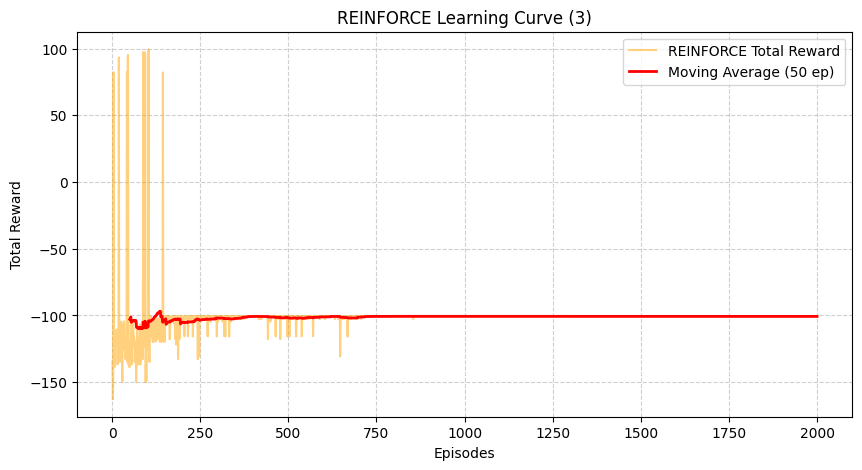

In [ ]:
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# 1. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 2

        # State: [d, c, p, m1, t1, m2, t2] = 7 dim
        # d, c, p: 0 or 1
        # m1, m2: 0 (No order), 1 (Cheese), 2 (Pepperoni)
        # t1, t2: 0 to 8 (Normalized by 8.0)
        self.observation_space = spaces.Box(
            low=0.0,
            high=np.array([1, 1, 1, 2, 1, 2, 1], dtype=np.float32),
            dtype=np.float32
        )
        self.action_space = spaces.Discrete(5)
        # 0: Idle, 1: Add Dough (d), 2: Add Cheese (c), 3: Add Pepperoni (p), 4: Serve

        self.menus = {
            1: [1.0, 1.0, 0.0], # Cheese Pizza: Dough + Cheese
            2: [1.0, 1.0, 1.0]  # Pepperoni Pizza: Dough + Cheese + Pepperoni
        }

        self.reset()

    def reset(self, seed=None):
        super().reset(seed=seed)
        self.counter = np.zeros(3, dtype=np.float32) # [d, c, p]
        self.orders = []

        # Initialize 2 orders with timer 4~8 steps
        for _ in range(self.max_orders):
            self._add_order()

        self.steps = 0
        self.terminated_count = 0
        return self._get_obs(), {}

    def _add_order(self):
        if len(self.orders) < self.max_orders:
            menu_id = np.random.choice([1, 2]) # Cheese or Pepperoni
            timer = np.random.randint(4, 9)     # 4 to 8 steps
            self.orders.append({'menu_id': menu_id, 'timer': timer})

    def _get_obs(self):
        obs = list(self.counter)
        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.append(float(self.orders[i]['menu_id']))
                obs.append(float(self.orders[i]['timer']) / 8.0)
            else:
                obs.append(0.0)
                obs.append(0.0)
        return np.array(obs, dtype=np.float32)

    def step(self, action):
        self.steps += 1
        reward = -0.1 # Every action penalty
        terminated = False
        truncated = self.steps >= 100

        # 1. Action Processing & Rule Checking
        if action == 1: # Add Dough
            if self.counter[0] == 1.0:
                reward -= 2.0 # Duplicate ingredient penalty
            else:
                self.counter[0] = 1.0
        elif action == 2: # Add Cheese
            if self.counter[1] == 1.0:
                reward -= 2.0 # Duplicate ingredient penalty
            elif self.counter[0] == 0.0:
                reward -= 2.0 # Incorrect sequence (needs dough first)
            else:
                self.counter[1] = 1.0
        elif action == 3: # Add Pepperoni
            if self.counter[2] == 1.0:
                reward -= 2.0 # Duplicate ingredient penalty
            elif self.counter[0] == 0.0 or self.counter[1] == 0.0:
                reward -= 2.0 # Incorrect sequence (needs dough & cheese first)
            else:
                self.counter[2] = 1.0
        elif action == 4: # Serve (FIFO based on orders[0])
            if len(self.orders) > 0:
                target_menu = self.orders[0]['menu_id']
                target_recipe = self.menus[target_menu]

                if np.array_equal(self.counter, target_recipe):
                    reward += 150.0 # ⭐ Correct serve reward (+20 -> +150)
                    self.orders.pop(0)
                    self.counter = np.zeros(3, dtype=np.float32) # Reset counter on correct serve
                else:
                    reward -= 15.0 # Incorrect serve penalty
                    self.counter = np.zeros(3, dtype=np.float32) # Reset counter on incorrect serve
            else:
                reward -= 1.0 # Serve with no orders

        # 2. Timer Update & Timeout Check for Waiting Orders
        orders_to_remove = []
        for order in self.orders:
            order['timer'] -= 1.0
            if order['timer'] <= 0:
                reward -= 50.0 # ⭐ Timeout penalty (-10 -> -50):
                orders_to_remove.append(order)

        for expired in orders_to_remove:
            if expired in self.orders:
                self.orders.remove(expired)

        # Episode termination condition: All orders completed or canceled
        if len(self.orders) == 0:
            terminated = True

        return self._get_obs(), reward, terminated, truncated, {}

# 2. Define Policy Network
class PolicyNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(PolicyNetwork, self).__init__()
        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, action_dim)
        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.softmax(self.fc3(x))
        return x

# 3. REINFORCE Training Function with History Tracking
def train_reinforce(env, policy_net, optimizer, num_episodes=2000, gamma=0.99):
    reward_history = []

    for episode in range(num_episodes):
        state, _ = env.reset()
        log_probs = []
        rewards = []

        done = False
        while not done:
            state_tensor = torch.FloatTensor(state).unsqueeze(0)
            probs = policy_net(state_tensor)

            m = torch.distributions.Categorical(probs)
            action = m.sample()

            log_probs.append(m.log_prob(action))

            next_state, reward, terminated, truncated, info = env.step(action.item())
            done = terminated or truncated

            rewards.append(reward)
            state = next_state

        total_reward = sum(rewards)
        reward_history.append(total_reward)

        # Calculate returns (Discounted cumulative rewards)
        returns = []
        G = 0
        for r in reversed(rewards):
            G = r + gamma * G
            returns.insert(0, G)

        returns = torch.tensor(returns, dtype=torch.float32)

        # Normalize returns for stability
        if len(returns) > 1 and returns.std() > 0:
            returns = (returns - returns.mean()) / (returns.std() + 1e-8)

        # Policy gradient update
        optimizer.zero_grad()
        policy_loss = []
        for log_prob, G in zip(log_probs, returns):
            policy_loss.append(-log_prob * G)

        loss = torch.sum(torch.stack(policy_loss))
        loss.backward()
        optimizer.step()

        if (episode + 1) % 50 == 0:
            print(f"Episode [{episode+1}/{num_episodes}] | Total Reward: {total_reward:.2f}")

    return reward_history

# 4. Execution
env = PizzaShopEnv()
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

policy_net = PolicyNetwork(state_dim, action_dim)
optimizer = optim.Adam(policy_net.parameters(), lr=0.001)

rewards_history = train_reinforce(env, policy_net, optimizer, num_episodes=2000)

# 5. Visualization
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(rewards_history) + 1), rewards_history, label='REINFORCE Total Reward', color='orange', alpha=0.5)

window_size = 50
if len(rewards_history) >= window_size:
    moving_avg = np.convolve(rewards_history, np.ones(window_size)/window_size, mode='valid')
    plt.plot(range(window_size, len(rewards_history) + 1), moving_avg, label=f'Moving Average ({window_size} ep)', color='red', linewidth=2)

plt.title('REINFORCE Learning Curve (3)')
plt.xlabel('Episodes')
plt.ylabel('Total Reward')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**현상**:

타임아웃 페널티를 -10에서 -50으로 강화하고, 정답 서빙 보상을 +20에서 +150까지 대폭 상향했음에도 불구하고 학습 성능이 개선되지 않았음. 오히려 학습이 진행될수록 에이전트의 총 보상이 주문 2개의 시간 초과에 따른 손실인 -100점 부근에 수렴하는 현상이 관찰됨.

**원인 분석**:

1. 초기 무작위 탐색 단계에서 에이전트가 엄격한 행동 순서 제약을 충족하는 성공적인 행동 경로를 발견할 확률이 낮음.

2. 학습 초기에 성공적인 행동 경로를 충분히 탐색하지 못하면서, 정책 신경망이 성공적인 서빙보다 소극적인 행동을 선택하는 방향으로 편향되었을 가능성이 있음.

3. 성공 보상을 아무리 높여도 에이전트가 해당 보상에 도달할 수 있는 행동 경로(Trajectory)를 탐색하지 못한다면, 보상 수치 조정만으로는 학습 부진을 해결하기 어려움.

**결론 및 시사점**:

3가지 보상 구조를 적용한 실험 결과, 기본 REINFORCE 알고리즘은 학습이 진행되어도 유의미한 성능 개선을 보이지 못하고, 주문 2개의 시간 초과에 따른 총 보상인 -100점 부근에 수렴하는 현상을 보였음.

특히 정답 서빙 보상을 +20에서 +150으로 대폭 높였음에도 학습 성능이 개선되지 않았다는 점에서, 단순히 보상 수치를 조정하는 것만으로는 현재 환경의 학습 부진을 해결하기 어렵다는 것을 확인함.

이러한 현상은 엄격한 행동 순서 제약과 희소 보상(Sparse Reward)으로 인해, 에이전트가 성공적인 행동 경로(Trajectory)를 충분히 탐색하지 못했기 때문일 가능성이 있음. 또한 REINFORCE의 Monte Carlo Return 기반 정책 경사 추정은 분산이 높아 학습 안정성에 불리하게 작용했을 가능성이 있음.

**알고리즘 발전 방향**:

기본 REINFORCE 실험을 통해 확인한 학습상의 한계를 개선하기 위해, 단순한 보상 튜닝을 넘어 가치 함수(Value Function)를 활용하는 알고리즘으로 발전시키고자 함.

먼저 REINFORCE with Baseline을 구현하여 Value Network가 상태별 기준 가치를 추정하도록 하고, 이를 바탕으로 Advantage를 계산하여 정책 경사 추정의 분산을 줄이는 방향으로 개선함.

이후 Actor-Critic 알고리즘을 적용하여 행동 정책(Actor)과 상태 가치 함수(Critic)를 함께 학습하고, TD(Temporal Difference) 기반의 Advantage 추정을 통해 정책을 보다 효율적으로 업데이트하고자 함.

이를 통해 각 알고리즘이 기존 REINFORCE의 학습 문제를 얼마나 개선하는지 동일한 환경과 평가 지표를 기준으로 비교, 분석할 계획임.

####
## 💡 **REINFORCE 종합 결론**

기본 REINFORCE 알고리즘을 적용한 총 3차례의 실험을 통해 정답 서빙 보상과 타임아웃 페널티의 변화가 학습 성능에 미치는 영향을 분석함.

초기 실험에서는 주문 처리에 성공하지 못하고 타임아웃이 반복되는 경향이 나타났으며, 타임아웃 페널티를 강화한 이후에도 학습 성능이 개선되지 않음. 이후 정답 서빙 보상을 +150으로 증가시켰으나, 평균 보상은 여전히 음수 구간에 머무르며 뚜렷한 성능 개선이 나타나지 않음.

이를 통해 본 실험 조건에서 기본 REINFORCE는 보상 구조를 조정하는 것만으로는 성공적인 주문 처리 정책을 충분히 학습하지 못했음을 확인함. 다만 이러한 결과를 알고리즘 자체의 일반적인 한계로 단정하기는 어려우며, 희소 보상 환경에서의 탐색 문제와 학습 과정의 높은 변동성이 영향을 미쳤을 가능성이 있음.

따라서 이후 실험에서는 가치 함수 기반 Baseline을 도입한 **REINFORCE with Baseline**을 적용하여 학습 성능의 변화를 확인하고자 함.